# 03. Preprocessing and features

**Goal.** Decide how the raw Effort columns become model inputs, and how the training labels are built, **using validation results only**.
The outer test groups are not touched here.

Three decisions are tested, each on the same 20 train / validation / test combinations from notebook 02:

1. **Which features, in which form?** Raw counts, signed log, with or without `E_RD`, with or without `E_CT`, capped or uncapped lines, a
   "no activity" flag, and team-relative versions (a student's commits compared with the rest of the same team in the same sprint).
2. **Which training labels?** Only the 9-15 rated records in the training groups, or those plus labels for the other records made by a
   small model fitted on the rated ones (and, optionally, the synthetic records).
3. **How much should the made-up labels count?** Weight 1 or 0.3.

**Leak-proof by construction.** The scaler and the label model are fitted on the training rows of each combination only (`training/features.py`).
The team-relative features use only the features of the same team and sprint, never labels.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("training").resolve()))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler

from common import RESULTS, SPLITS, environment, group_bootstrap, load, log_run, metrics
from features import (ALPHAS, LABEL_SOURCES, REAL_ONLY, VARIANTS, Propagator, add_team_context, design, fit_predict_ridge,
                      training_set)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
d = add_team_context(load().set_index("record_id", drop=False))
splits = pd.read_csv(SPLITS)
combos = [(t, v, g[["record_id", "role"]]) for (t, v), g in splits.groupby(["outer_test", "inner_val"])]
GOLD = d[d.label_source == "rater"]
print(environment())
print(len(combos), "combinations;", len(GOLD), "rated records;", len(VARIANTS), "feature variants")

{'python': '3.11.14', 'numpy': '2.4.6', 'pandas': '3.0.6', 'scipy': '1.17.1', 'sklearn': '1.9.1', 'seed': 20261018, 'data_hash': '2a23bdaa674b', 'splits_hash': 'b5793a57b501'}
20 combinations; 20 rated records; 12 feature variants


## 1. The feature variants

In [2]:
pd.DataFrame({"inputs": {name: ", ".join(f"{c}{' (log)' if tf == 'log' else ''}" for c, tf in spec) for name, spec in VARIANTS.items()},
              "needs a team": {name: ("yes" if name in REAL_ONLY else "") for name in VARIANTS}})

,inputs,needs a team
raw5,"E_CC, E_LOC_net_capped, E_FC, E_CT, E_RD",
log5,"E_CC (log), E_LOC_net_capped (log), E_FC (log)...",
log4 (no RD),"E_CC (log), E_LOC_net_capped (log), E_FC (log)...",
"log3 (commits, lines, files)","E_CC (log), E_LOC_net_capped (log), E_FC (log)",
"log5, RD marked n/a","E_CC (log), E_LOC_net_capped (log), E_FC (log)...",
log4 + RD marked n/a,"E_CC (log), E_LOC_net_capped (log), E_FC (log)...",
log3 + RD marked n/a,"E_CC (log), E_LOC_net_capped (log), E_FC (log)...",
log4 + no-activity flag,"E_CC (log), E_LOC_net_capped (log), E_FC (log)...",
"log4, uncapped lines","E_CC (log), E_LOC_net (log), E_FC (log), E_CT ...",
log4 + team z-scores,"E_CC (log), E_LOC_net_capped (log), E_FC (log)...",yes


Team-relative variants compare a student with the rest of the same team in the same sprint (z-score of log values, and share of the team's
total). They exist only for real records, because synthetic records have no team.

In [3]:
ex = d[(d.team_id == "T04") & (d.sprint_id == "T04-S2")][["student_id", "E_CC", "E_CC_team_z", "E_CC_team_share", "E_FC", "E_FC_team_z"]]
ex.round(2)

,student_id,E_CC,E_CC_team_z,E_CC_team_share,E_FC,E_FC_team_z
record_id,,,,,,
T04-S2-STU-005,STU-005,5,0.87,0.42,64,0.89
T04-S2-STU-012,STU-012,5,0.87,0.42,43,0.55
T04-S2-STU-027,STU-027,1,-0.87,0.08,4,-1.38
T04-S2-STU-010,STU-010,1,-0.87,0.08,21,-0.07


## 2. Proof that nothing leaks

For one combination, the scaler inside the model is fitted on the training rows only. We check that its mean equals the training mean, and
that changing the validation features does not change it.

In [4]:
test, val, roles = combos[0]
X, y, w, ids = training_set(d, roles, "log4 (no RD)", "rated + propagated (real)")
_, pipe = fit_predict_ridge(X, y, w, design(d.loc[roles[roles.role == "val"].record_id], "log4 (no RD)"), alpha=1.0)
scaler = pipe.named_steps["standardscaler"]
assert np.allclose(scaler.mean_, X.mean(axis=0)), "scaler was not fitted on the training rows"

# change every validation and test feature drastically: nothing learned may change
d2 = d.copy()
held = roles[roles.role.isin(["val", "test"])].record_id
d2.loc[held, ["E_CC", "E_LOC_net_capped", "E_FC", "E_CT"]] = 9999
X2, y2, w2, ids2 = training_set(d2, roles, "log4 (no RD)", "rated + propagated (real)")
assert np.array_equal(X, X2) and np.allclose(y, y2), "training data changed when validation or test rows changed"
print("OK: scaler and propagated labels depend only on the training rows")
print("training rows in this combination:", len(ids), "| rated:", int((w == 1).sum()), "| propagated:", int((w != 1).sum()) if w.min() != 1 else 0)

OK: scaler and propagated labels depend only on the training rows
training rows in this combination: 45 | rated: 45 | propagated: 0


## 3. Label construction

For unrated rows the label comes from a Ridge model fitted on the rated rows of the training groups. How good is that model on held-out
rated rows? That is the quality of the labels the later models would be learning from.

In [5]:
rows = []
for test, val, roles in combos:
    t = d.loc[roles[roles.role == "train"].record_id]
    gold = t[(t.source == "real") & (t.label_source == "rater")]
    prop = Propagator(gold)
    v = d.loc[[i for i in roles[(roles.role == "val")].record_id if i in GOLD.index]]
    p = prop.predict(v)
    rows += [(test, val, r, y, yh, a) for r, y, yh, a in zip(v.record_id, v.rater_effort, p, [prop.alpha] * len(v))]
lab = pd.DataFrame(rows, columns=["outer_test", "inner_val", "record_id", "y", "pred", "alpha"])
m = metrics(lab.y, lab.pred)
print(f"label model on held-out rated records: MAE {m['MAE']:.3f}, RMSE {m['RMSE']:.3f}, Pearson {m['pearson']:.3f}, n={m['n']} predictions")
print("alpha chosen per combination:", sorted(lab.alpha.unique()))

label model on held-out rated records: MAE 0.073, RMSE 0.108, Pearson 0.905, n=80 predictions
alpha chosen per combination: [np.float64(0.01), np.float64(0.1), np.float64(0.31622776601683794), np.float64(1.0), np.float64(3.1622776601683795)]


The propagated labels are only as good as this error. Any model trained on them can at best learn what this model already says, which is
why "rated only" is kept as an option and compared below.

## 4. The experiment

For every variant, label source, weight and three `alpha` values (0.1, 1, 10): train Ridge on the training rows of each combination, predict
the rated records of the validation group, and pool over the 20 combinations. `alpha` is only varied here to check the conclusion does not
depend on it; it is tuned properly in notebook 04.

In [6]:
WEIGHTS = [1.0, 0.3]
ALPHA_GRID = [0.1, 1.0, 10.0]
records = []
for variant in VARIANTS:
    for source in LABEL_SOURCES:
        if variant in REAL_ONLY and source == LABEL_SOURCES[2]:
            continue  # no synthetic rows for team-relative features
        for weight in (WEIGHTS if source != "rated only" else [1.0]):
            for test, val, roles in combos:
                X, y, w, ids = training_set(d, roles, variant, source, weight)
                v = d.loc[[i for i in roles[roles.role == "val"].record_id if i in GOLD.index]]
                for alpha in ALPHA_GRID:
                    p, _ = fit_predict_ridge(X, y, w, design(v, variant), alpha)
                    records += [(variant, source, weight, alpha, test, val, r, g, yy, pp, cc)
                                for r, g, yy, pp, cc in zip(v.record_id, v.group, v.rater_effort, p, v.E_CC)]
res = pd.DataFrame(records, columns=["variant", "label_source", "weight", "alpha", "outer_test", "inner_val", "record_id", "group", "y", "pred", "E_CC"])
res["abs_err"] = (res.pred - res.y).abs()
res.to_csv(RESULTS / "preprocessing_validation_predictions.csv", index=False)
print(len(res), "predictions;", res.groupby(["variant", "label_source", "weight"]).ngroups, "configurations")

12960 predictions; 54 configurations


## 5. Results

In [7]:
cfg = ["variant", "label_source", "weight"]
table = (res.groupby(cfg + ["alpha"]).abs_err.mean().groupby(cfg).mean().rename("MAE (mean over alpha)").reset_index())
active = res[res.E_CC > 0].groupby(cfg).abs_err.mean().rename("MAE active only").reset_index()
table = table.merge(active, on=cfg).sort_values("MAE (mean over alpha)").reset_index(drop=True)
table.round(3).head(15)

,variant,label_source,weight,MAE (mean over alpha),MAE active only
0,log4 + no-activity flag,rated only,1.0,0.061,0.071
1,log4 (no RD),rated only,1.0,0.062,0.071
2,"log4, uncapped lines",rated + propagated (real),0.3,0.062,0.072
3,log4 (no RD),rated + propagated (real),0.3,0.063,0.073
4,"log4, uncapped lines",rated only,1.0,0.063,0.071
5,"log4, uncapped lines",rated + propagated (real),1.0,0.063,0.073
6,log4 (no RD),rated + propagated (real),1.0,0.063,0.074
7,log4 (no RD),rated + propagated (real + synthetic),0.3,0.064,0.074
8,log4 (no RD),rated + propagated (real + synthetic),1.0,0.064,0.075
9,log4 + no-activity flag,rated + propagated (real),0.3,0.064,0.075


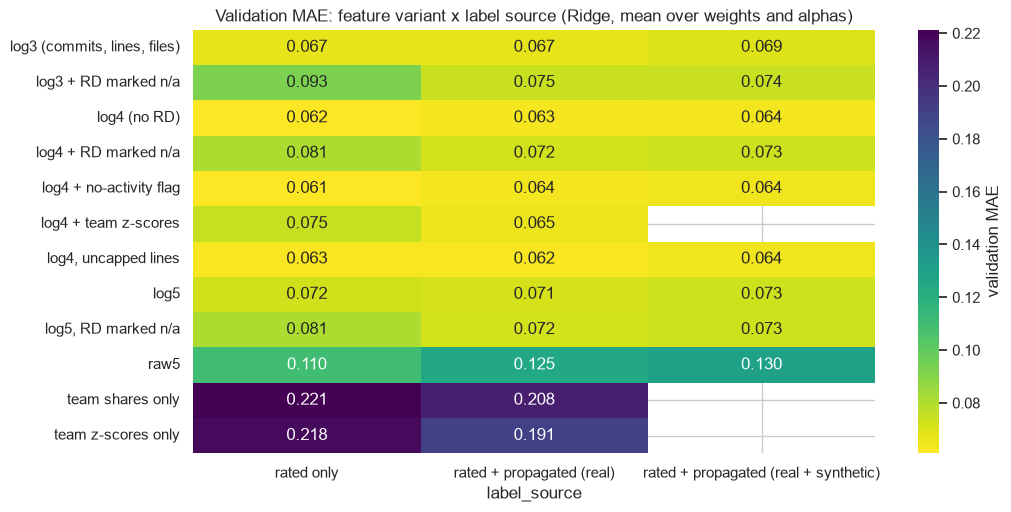

reference from notebook 02: commits alone 0.061 (linear) / 0.053 (normalised); Ridge on all five log features 0.073


In [8]:
pivot = res.groupby(["variant", "label_source"]).abs_err.mean().unstack("label_source")[LABEL_SOURCES]
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis_r", ax=ax, cbar_kws={"label": "validation MAE"})
ax.set(title="Validation MAE: feature variant x label source (Ridge, mean over weights and alphas)", ylabel="")
plt.show()
print("reference from notebook 02: commits alone 0.061 (linear) / 0.053 (normalised); Ridge on all five log features 0.073")

In [9]:
sub = res[res.label_source == LABEL_SOURCES[1]].groupby(["variant", "weight"]).abs_err.mean().unstack("weight")
sub.round(3)

weight,0.3,1.0
variant,,
"log3 (commits, lines, files)",0.067,0.067
log3 + RD marked n/a,0.077,0.073
log4 (no RD),0.063,0.063
log4 + RD marked n/a,0.072,0.071
log4 + no-activity flag,0.064,0.064
log4 + team z-scores,0.066,0.065
"log4, uncapped lines",0.062,0.063
log5,0.072,0.071
"log5, RD marked n/a",0.072,0.071


## 6. Choosing, by a rule written before looking

In [10]:
# rule: lowest mean validation MAE; then the SIMPLEST configuration within one bootstrap standard error of it
def simplicity(row):
    n_features = len(VARIANTS[row.variant])
    label_rank = LABEL_SOURCES.index(row.label_source)
    return (n_features, label_rank, row.weight != 1.0)

best = table.iloc[0]
sel = res[(res.variant == best.variant) & (res.label_source == best.label_source) & (res.weight == best.weight)]
boot = []
rng = np.random.default_rng(20261018)
groups = sel.group.unique()
for _ in range(1000):
    pick = rng.choice(groups, len(groups), replace=True)
    boot.append(np.mean(np.concatenate([sel[sel.group == g].abs_err.to_numpy() for g in pick])))
se = float(np.std(boot))
limit = best["MAE (mean over alpha)"] + se
near = table[table["MAE (mean over alpha)"] <= limit].copy()
near["rank"] = near.apply(simplicity, axis=1)
choice = near.sort_values("rank").iloc[0]
print(f"best: {best.variant} | {best.label_source} | weight {best.weight} | MAE {best['MAE (mean over alpha)']:.3f}   (SE {se:.3f})")
print(f"configurations within one SE: {len(near)}")
print(f"chosen (simplest within one SE): {choice.variant} | {choice.label_source} | weight {choice.weight} | MAE {choice['MAE (mean over alpha)']:.3f}")
near.drop(columns="rank").round(3)

best: log4 + no-activity flag | rated only | weight 1.0 | MAE 0.061   (SE 0.009)
configurations within one SE: 21
chosen (simplest within one SE): log3 (commits, lines, files) | rated only | weight 1.0 | MAE 0.067


,variant,label_source,weight,MAE (mean over alpha),MAE active only
0,log4 + no-activity flag,rated only,1.0,0.061,0.071
1,log4 (no RD),rated only,1.0,0.062,0.071
2,"log4, uncapped lines",rated + propagated (real),0.3,0.062,0.072
3,log4 (no RD),rated + propagated (real),0.3,0.063,0.073
4,"log4, uncapped lines",rated only,1.0,0.063,0.071
5,"log4, uncapped lines",rated + propagated (real),1.0,0.063,0.073
6,log4 (no RD),rated + propagated (real),1.0,0.063,0.074
7,log4 (no RD),rated + propagated (real + synthetic),0.3,0.064,0.074
8,log4 (no RD),rated + propagated (real + synthetic),1.0,0.064,0.075
9,log4 + no-activity flag,rated + propagated (real),0.3,0.064,0.075


In [11]:
decision = {"variant": choice.variant, "label_source": choice.label_source, "pseudo_weight": float(choice.weight),
            "features": [c for c, _ in VARIANTS[choice.variant]], "validation_MAE": round(float(choice["MAE (mean over alpha)"]), 4),
            "standard_error": round(se, 4), "rule": "lowest validation MAE, then simplest within one bootstrap SE"}
(RESULTS / "preprocessing_choice.json").write_text(json.dumps(decision, indent=2))
log_run("03_preprocessing_and_features", choice.variant, f"chosen; {choice.label_source}; weight {choice.weight}; validation, pooled over 20 combinations",
        {"MAE": decision["validation_MAE"], "SE": decision["standard_error"]})
print(json.dumps(decision, indent=2))

{
  "variant": "log3 (commits, lines, files)",
  "label_source": "rated only",
  "pseudo_weight": 1.0,
  "features": [
    "E_CC",
    "E_LOC_net_capped",
    "E_FC"
  ],
  "validation_MAE": 0.0669,
  "standard_error": 0.0087,
  "rule": "lowest validation MAE, then simplest within one bootstrap SE"
}


## 7. Reading the results

Validation MAE, pooled over the 20 combinations, Ridge:

| Question | Answer from the tables above |
|---|---|
| Is the log transform needed? | **Yes.** Raw counts give 0.126; the same features in signed log give 0.07 or better. |
| Should `E_RD` stay? | **No.** Dropping it improves MAE from 0.072 (5 features) to 0.063 (4 features). |
| Does marking `E_RD` as *not applicable* fix that? | **No.** Where the team opened no pull requests (53 of 144 real records) a review was impossible, so those records get a flag next to `E_RD = 0`. Result: 5 features with the flag 0.071 (same as without), 4 features + `E_RD` + flag 0.071-0.072 (vs 0.063 without `E_RD`), 3 features + `E_RD` + flag 0.073-0.077 (vs 0.067). |
| Why does `E_RD` not help even when marked correctly? | Only 13 real records, and 3 of the 20 rated ones, have any review activity. Among rated records where a review was possible (14), the correlation of `E_RD` with the label is 0.06, against 0.87 for commits. The model has almost nothing to learn its effect from. |
| Should `E_CT` (tasks done) stay? | **Not clearly.** Removing it (3 features) costs 0.004, well inside the standard error of 0.009. It also comes from the reconstructed board, and every record has at least one assigned task, so there is nothing to mark as missing. |
| Capped or uncapped lines? | No difference (0.062 vs 0.063). |
| A "no activity" flag? | No gain (0.061 vs 0.062). The log of zero commits is already zero. |
| Team-relative features? | **No.** Used alone they are far worse (0.19-0.21); added to the log features they are slightly worse (0.065). |
| Do propagated labels help? | **No.** Rated records only is as good as, or marginally better than, adding propagated labels (0.061-0.062 vs 0.063-0.064). |
| Do synthetic records help? | **No.** Adding them changes MAE by less than 0.001. |
| Does the weight on propagated labels matter? | No (0.3 vs 1.0 differ by 0.001). |

**What the rule chose.** Every sensible variant lies within about one standard error of the best, so the data cannot separate them. The
rule (simplest within one SE of the best) selects `log3 (commits, lines, files)`, rated labels only, MAE 0.067. This is saved to
`training/results/preprocessing_choice.json` for notebooks 04-08.

**What it means.**
- Cleaning and transforming the features matters (raw -> log, dropping `E_RD`), but beyond that nothing separates the variants.
- The proposal's review feature fails here because of the data, not the handling: almost nobody wrote reviews. A cohort that uses pull
  requests with real review would let it be tested properly.
- None of the variants beats commit count alone (0.061 linear, 0.053 normalised from notebook 02). With only 9-15 rated records per fold,
  extra inputs add variance and no new information.
- Propagated labels and synthetic records add nothing for training Ridge. They remain useful for giving every student a mark with an
  interval, but they do not make the Effort model better.
- Notebook 04 therefore tests whether Random Forest or Gradient Boosting find something Ridge cannot, on the proposal's five features,
  the five features with `E_RD` marked not applicable (Gradient Boosting can read the missing value directly), and the chosen three.